# Conditional Diffusion Generator

Andrew H. Fagg

Advanced Machine Learning


In [1]:
%reload_ext autoreload
%autoreload 2

import sys

import argparse
import copy
import pickle
import random
from chesapeake_loader import *
from diffusion_tools import *

import tensorflow as tf
import keras
from keras.models import Sequential

from keras.layers import Concatenate, UpSampling2D, Add
from keras.layers import Convolution2D, Dense, MaxPooling2D, GlobalMaxPooling2D, Flatten, BatchNormalization, Dropout, SpatialDropout2D
from keras import Input, Model
from matplotlib import colors
from keras.utils import plot_model


#################################################################
# Default plotting parameters
FIGURESIZE=(10,6)
FONTSIZE=18

plt.rcParams['figure.figsize'] = FIGURESIZE
plt.rcParams['font.size'] = FONTSIZE

plt.rcParams['xtick.labelsize'] = FONTSIZE-2
plt.rcParams['ytick.labelsize'] = FONTSIZE-2

#################################################################



2025-04-23 22:08:57.204638: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-23 22:08:57.226031: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-04-23 22:08:57.226053: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-23 22:08:57.227003: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-23 22:08:57.231126: I tensorflow/core/platform/cpu_feature_gua

In [2]:
# Configure the GPU
visible_devices = tf.config.get_visible_devices('GPU')
for device in visible_devices:
    tf.config.experimental.set_memory_growth(device, True)

In [2]:
# Turn off the GPU
tf.config.set_visible_devices([], 'GPU')

2025-04-23 22:08:59.478258: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-04-23 22:08:59.502758: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-04-23 22:08:59.502912: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [4]:
# Load model
fname = 'results/unet_None_filt_32_32_16_steps_3_sdrop_0.100_R0'   


model = keras.models.load_model(fname + '_model.keras', custom_objects={'PositionEncoder': PositionEncoder,
                                                                     'ExpandDims': keras.src.ops.numpy.ExpandDims,
                                                                     'Tile': keras.src.ops.numpy.Tile,
                                                                     'mse': 'mse'})

with open(fname + '_results.pkl', 'rb') as fp:
    results = pickle.load(fp)

In [5]:
results.keys()

dict_keys(['args', 'predict_validation_eval', 'predict_training_eval', 'history', 'fname_base'])

In [6]:
args=results['args']
args

Namespace(project='Chesapeake-Diffusion', check=False, nogo=False, force=False, verbose=7, cpus_per_task=None, gpu=True, exp_type=None, timesteps=50, time_embedding_len=20, beta_start=0.0001, beta_end=0.1, beta_schedule='linear', time_sampling_exponent=0.5, label=None, dataset='/home/fagg/datasets/radiant_earth/pa', image_size=[32, 32, 3], model_dir=None, Nfolds=10, results_path='./results', exp_index=None, rotation=0, epochs=1000, train_filt='*[012345678]', lrate=0.0001, clipnorm=0.001, conv_nfilters=[32, 32, 16], steps=3, activation_conv='elu', activation_output='linear', batch_normalization=False, spatial_dropout=0.1, L2_regularization=None, min_delta=0.0, patience=30, monitor='val_loss', batch=16, prefetch=2, num_parallel_calls=4, cache=None, shuffle=200, repeat=True, steps_per_epoch=32, steps_per_validation_epoch=None, render=True, save_model=False)

In [17]:
patch_size=args.image_size[0]
patch_size=32
file_base = '/home/fagg/datasets/radiant_earth/pa'
# Must match parameters used for training
timesteps = args.timesteps
beta, alpha, gamma = compute_beta_alpha2(timesteps, args.beta_end, args.beta_start, 0, 0.1)


In [18]:
# Sampling data set
ds = create_single_dataset(base_dir=file_base, 
                         full_sat=False,
                         partition='valid',
                         patch_size=patch_size, 
                         fold=0,
                         cache_path=None, 
                         repeat=True, 
                         batch_size=batch_size, 
                         prefetch=2, 
                         num_parallel_calls=4)


In [19]:
# Check shapes
for I, L in ds.take(1):
    print(I.numpy().shape, L.numpy().shape)

(8, 32, 32, 3) (8, 32, 32, 7)


2025-04-23 22:12:37.605316: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [20]:
I.numpy().shape

(8, 32, 32, 3)

In [21]:
# Inference with loaded I/L
TS = list(range(timesteps))
stepdata = list(zip(TS, beta, alpha, gamma))
stepdata.reverse()
print(TS)
# Random noise
Z = np.random.normal(loc=0, scale=1.0, size=I.shape)
print("SHAPE:", Z.shape)
Zs = []

# Loop over timesteps
for ts, b, a, g in stepdata:
    for st in range(1):
        Zs.append(Z)
    
        # All examples get the same time index
        t_tensor = ts * np.ones(shape=(I.shape[0], 1))
    
        # Predict the noise
        delta = model.predict(x={'image_input': Z, 'time_input': t_tensor, 'label_input': L})

        print(np.min(delta[0,:,:,:]), np.max(delta[0,:,:,:]), np.mean(delta[0,:,:,:]), np.std(delta[0,:,:,:]))
        
        print(ts,a,b)
    
        # Adjust the image
        Z = Z/np.sqrt(1-b) - delta * b / (np.sqrt(1-a) * np.sqrt(1-b))

        #Z = np.maximum(Z, -1)
        #Z = np.minimum(Z, 1)
 
    
        if ts > 0:
            # Add exploratory noise
            noise = np.random.normal(loc=0, scale=1.0, size=I.shape)
            Z = Z + g * noise

# Final step
Zs.append(Z)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]
SHAPE: (8, 32, 32, 3)


2025-04-23 22:12:39.391480: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 940ms/step
-3.1855898 3.1764886 -0.007441657 0.9587253
49 0.14475621156096724 0.00014929461946341926
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
-3.131358 3.180506 -0.00649609 0.96705866
48 0.14477782611142329 0.0002971298300156744
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
-3.1416326 3.2162685 -0.0049116127 0.97193044
47 0.14482085670795963 0.0005433597361523129
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
-3.03076 3.0947556 -0.0046550357 0.9782608
46 0.144899589310576 0.0008877413386836619
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
-3.129632 3.171996 -0.0046306103 0.9895565
45 0.14502833696057646 0.001329934774545738
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
-3.0490031 3.2209084 -0.004769247 1.002232
44 0.14522147204626148 0.0018695036522040076
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
-3.1337814 3.3179014 -0.004277325 1.0172406
43 0.14549347262470522 0.0025059154823191404
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
-3.14946 3.2740953 -0.0025661818 1.0289706
42 0.14585898290821023 0.003238542

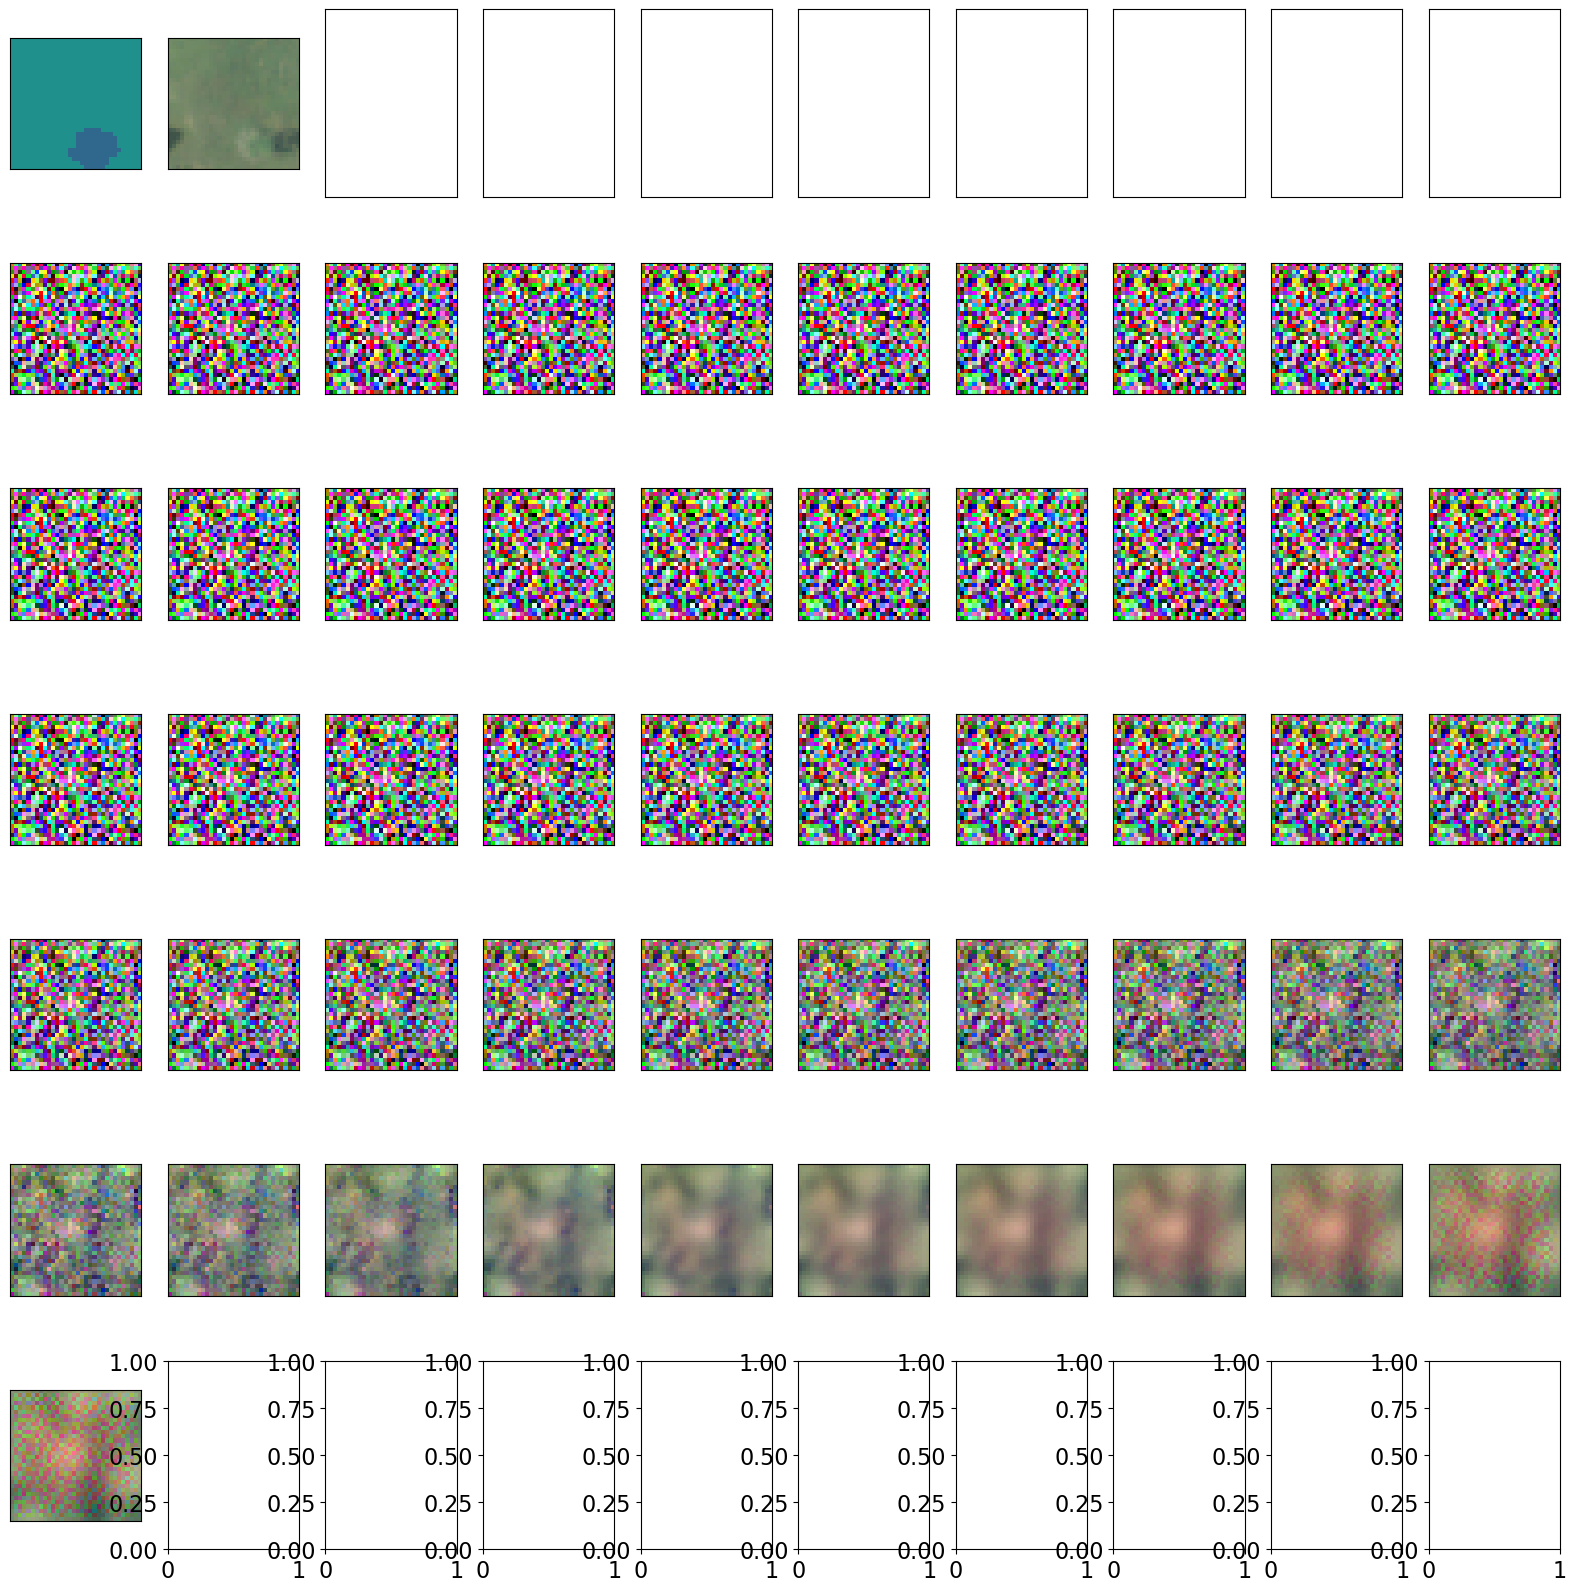

In [23]:
# Visualization
#   You will need to play with this

i=0
cols = 10
fig, axs = plt.subplots(len(Zs)//cols+2, cols, figsize=(20,20))

cl = np.argmax(L[i,:,:,:], axis=-1)
axs[0,0].imshow(cl, vmax=6, vmin=0)
axs[0,1].imshow(I[i,:,:,:])

for j in range(cols):
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])


for j, Z in enumerate(Zs):
    axs[j//cols+1, j%cols].imshow(convert_image(Z[i,:,:,:]))
    axs[j//cols+1, j%cols].set_xticks([])
    axs[j//cols+1, j%cols].set_yticks([])



([], [])

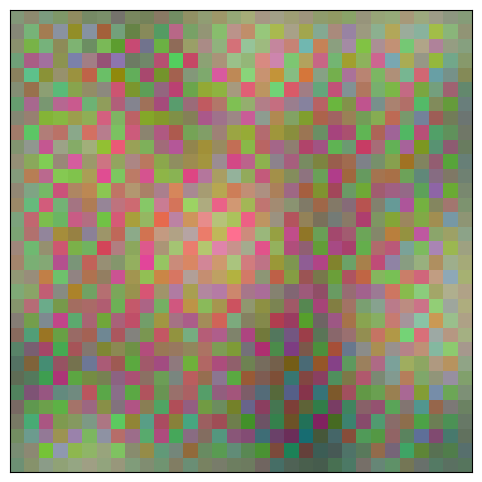

In [24]:
# Last image
plt.imshow(convert_image(Zs[-1][i,:,:,:]))
plt.xticks([])
plt.yticks([])